# Análisis de precios de Airbnb en Madrid

## 1. Contexto y objetivo del proyecto

Una empresa del sector inmobiliario dispone de viviendas anunciadas en Airbnb en Madrid y busca identificar oportunidades para optimizar sus precios de alojamiento.

La pregunta principal que plantea el proyecto es:

**¿Qué características de las viviendas están asociadas con las diferencias de precio y cómo pueden utilizarse estos resultados para orientar una estrategia de precios?**

Para abordar esta cuestión, se analizarán los precios de los alojamientos completos en función de sus características físicas, ubicación, valoraciones y condiciones de los anfitriones.

El objetivo es identificar patrones y diferencias relevantes que permitan comprender mejor el comportamiento de los precios en el mercado analizado.

## 2. Descripción de los datos


El análisis utiliza cinco datasets de alojamientos Airbnb en Madrid, con información sobre las características de las viviendas, sus anfitriones, ubicación, condiciones de alquiler y valoraciones.

| Dataset | Descripción |
|---|---|
| `airbnb_madrid_conditions.csv` | Precio por noche y condiciones de alquiler. |
| `airbnb_madrid_host.csv` | Características y condiciones de los anfitriones. |
| `airbnb_madrid_location.csv` | Ubicación geográfica, barrio, distrito y distancias a puntos de referencia. |
| `airbnb_madrid_property.csv` | Características físicas, capacidad y equipamiento de las viviendas. |
| `airbnb_madrid_reviews.csv` | Número de reseñas y valoraciones de los huéspedes. |

Cada dataset contiene 21.020 registros y utiliza el identificador `id` para relacionar la información de los alojamientos.

Para el análisis se seleccionarán únicamente viviendas completas, con el objetivo de comparar alojamientos de una misma modalidad.

## 3. Carga de datos

### 3.1. Importación de librerías

In [1]:
#Librerías:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 3.2. Carga de datasets

In [2]:
# Carga de los cinco datasets desde la carpeta data/
from pathlib import Path

carpeta_datos = Path("data")

condiciones_cada_vivienda = pd.read_csv(carpeta_datos / "airbnb_madrid_conditions.csv")
propietario_cada_vivienda = pd.read_csv(carpeta_datos / "airbnb_madrid_host.csv")
localizacion_vivienda = pd.read_csv(carpeta_datos / "airbnb_madrid_location.csv")
vivienda = pd.read_csv(carpeta_datos / "airbnb_madrid_property.csv")
reseñas = pd.read_csv(carpeta_datos / "airbnb_madrid_reviews.csv")

## 4. Exploración inicial de los datos

### 4.1. Condiciones del alquiler

In [3]:
# Vista inicial de los datos de condiciones de alquiler

condiciones_cada_vivienda.head()

,id,price,minimum_nights,maximum_nights,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification
0,0,70.0,1,365,flexible,0,0
1,1,17.0,4,40,strict_14_with_grace_period,0,0
2,2,50.0,15,730,moderate,0,0
3,3,80.0,5,730,moderate,0,0
4,4,115.0,3,10,moderate,0,0


In [4]:
# Revisar la estructura y los tipos de datos

condiciones_cada_vivienda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21020 entries, 0 to 21019
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                21020 non-null  int64  
 1   price                             21020 non-null  float64
 2   minimum_nights                    21020 non-null  int64  
 3   maximum_nights                    21020 non-null  int64  
 4   cancellation_policy               21020 non-null  object 
 5   require_guest_profile_picture     21020 non-null  int64  
 6   require_guest_phone_verification  21020 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.1+ MB


In [5]:
# Estadísticas descriptivas de precios y condiciones de estancia

condiciones_cada_vivienda[
    ["price", "minimum_nights", "maximum_nights"]
].describe()

,price,minimum_nights,maximum_nights
count,21020.000000,21020.000000,2.102000e+04
mean,131.326213,4.414843,1.276126e+03
std,364.802634,21.745342,7.664670e+04
min,1.000000,1.000000,1.000000e+00
25%,40.000000,1.000000,4.000000e+01
50%,65.000000,2.000000,1.125000e+03
75%,102.000000,3.000000,1.125000e+03
max,9999.000000,1125.000000,1.111111e+07


Los precios presentan una diferencia considerable entre la media (131,33 €) y la mediana (65 €), lo que sugiere una distribución asimétrica influida por alojamientos de precio elevado.

También se observan valores extremos en las condiciones de estancia. Estos se tendrán en cuenta durante la preparación y el análisis, sin aplicar tratamientos automáticos.

### 4.2. Características de los anfitriones

In [6]:
# Vista inicial de los datos de los anfitriones

propietario_cada_vivienda.head()

,id,host_response_time,host_response_rate,host_is_superhost,host_has_profile_pic,host_identity_verified,host_verifications_email,host_verifications_phone,host_verifications_reviews,host_verifications_facebook,host_verifications_government_id,calculated_host_listings_count,host_seniority
0,0,within_an_hour,100.0,1,1,0,1,1,1,0,1,1,3921
1,1,NaN,NaN,0,1,1,1,1,1,0,1,2,3610
2,2,within_an_hour,100.0,0,1,0,1,1,1,0,1,6,3614
3,3,within_a_few_hours,100.0,0,1,1,1,1,1,1,1,1,3572
4,4,within_an_hour,100.0,1,1,0,1,1,1,1,0,1,3572


In [7]:
# Revisar la estructura y los tipos de datos de los anfitriones

propietario_cada_vivienda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21020 entries, 0 to 21019
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                21020 non-null  int64  
 1   host_response_time                16556 non-null  object 
 2   host_response_rate                16556 non-null  float64
 3   host_is_superhost                 21020 non-null  int64  
 4   host_has_profile_pic              21020 non-null  int64  
 5   host_identity_verified            21020 non-null  int64  
 6   host_verifications_email          21020 non-null  int64  
 7   host_verifications_phone          21020 non-null  int64  
 8   host_verifications_reviews        21020 non-null  int64  
 9   host_verifications_facebook       21020 non-null  int64  
 10  host_verifications_government_id  21020 non-null  int64  
 11  calculated_host_listings_count    21020 non-null  int64  
 12  host

Se analizan la condición de Superhost y el número de propiedades asociadas a cada anfitrión para conocer su distribución y valorar su relevancia en el análisis de precios.

In [8]:
# Estadísticas descriptivas de los anfitriones
propietario_cada_vivienda[
    ["host_is_superhost", "calculated_host_listings_count"]
].describe()

,host_is_superhost,calculated_host_listings_count
count,21020.000000,21020.00000
mean,0.203330,11.54648
std,0.402486,32.29336
min,0.000000,1.00000
25%,0.000000,1.00000
50%,0.000000,2.00000
75%,0.000000,7.00000
max,1.000000,252.00000


In [9]:
# Frecuencia del número de alojamientos por anfitrión

propietario_cada_vivienda["calculated_host_listings_count"].value_counts().head(20)

calculated_host_listings_count
1      9312
2      2813
3      1463
4       840
6       644
5       634
9       400
7       377
8       335
252     248
10      233
11      195
12      178
13      168
26      153
20      139
15      134
132     132
19      128
14      124
Name: count, dtype: int64

El 44,3 % de los alojamientos corresponde a anfitriones con una sola propiedad, aunque también se observan carteras de mayor tamaño. Los resultados se interpretan por alojamiento, no por anfitrión único.

### 4.3. Ubicación de los alojamientos

In [10]:
# Vista inicial de los datos de ubicación

localizacion_vivienda.head()

,id,neighbourhood,neighbourhood_group,latitude,longitude,dist_km_sol,dist_km_airport
0,0,Chamartín,Chamartín,40.45628,-3.67763,6.769415,11.162062
1,1,Aluche,Latina,40.40341,-3.74084,4.433720,18.198818
2,2,Legazpi,Arganzuela,40.38695,-3.69304,4.552379,15.799212
3,3,Malasaña,Centro,40.42202,-3.70395,1.848181,14.020964
4,4,Justicia,Centro,40.41995,-3.69764,2.317480,13.364384


In [11]:
# Revisar la estructura y los tipos de datos de ubicación

localizacion_vivienda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21020 entries, 0 to 21019
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   21020 non-null  int64  
 1   neighbourhood        21020 non-null  object 
 2   neighbourhood_group  21020 non-null  object 
 3   latitude             21020 non-null  float64
 4   longitude            21020 non-null  float64
 5   dist_km_sol          21020 non-null  float64
 6   dist_km_airport      21020 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 1.1+ MB


In [12]:
# Estadísticas descriptivas de las distancias

localizacion_vivienda[
    ["dist_km_sol", "dist_km_airport"]
].describe()

,dist_km_sol,dist_km_airport
count,21020.000000,21020.000000
mean,3.921288,13.717463
std,2.824069,2.665593
min,0.000000,0.720670
25%,1.930370,13.081924
50%,2.815954,13.998700
75%,5.292589,14.845695
max,19.433900,25.225935


Los alojamientos se sitúan a una distancia mediana de 2,82 km de Sol y 14 km del aeropuerto. La mayor diferencia entre media y mediana en la distancia a Sol sugiere una distribución asimétrica, que se tendrá en cuenta al analizar su relación con el precio.

In [13]:
# Distribución de alojamientos por distrito

localizacion_vivienda["neighbourhood_group"].value_counts()

neighbourhood_group
Centro                   9804
Salamanca                1366
Chamberí                 1274
Arganzuela               1159
Tetuán                    874
Carabanchel               664
Retiro                    654
Ciudad Lineal             636
Puente de Vallecas        625
Latina                    621
Moncloa - Aravaca         573
Chamartín                 559
San Blas - Canillejas     547
Usera                     375
Hortaleza                 351
Fuencarral - El Pardo     291
Barajas                   185
Villaverde                176
Moratalaz                 121
Villa de Vallecas         100
Vicálvaro                  65
Name: count, dtype: int64

El distrito Centro concentra el 46,6 % de los alojamientos. La distribución desigual entre distritos deberá considerarse al comparar sus precios, especialmente en aquellos con menor representación.

In [14]:
# Distribución de alojamientos por barrio

localizacion_vivienda["neighbourhood"].value_counts()

neighbourhood
Centro            5058
Embajadores       1192
Malasaña           767
Salamanca          691
Carabanchel        668
                  ... 
Nueva España        28
Castilla            22
El Tréntaiseis      15
Estrella            15
Atocha               7
Name: count, Length: 66, dtype: int64

Los alojamientos se distribuyen entre 66 barrios, con una elevada concentración en Centro. Las diferencias en el tamaño de las muestras deberán considerarse al comparar los precios por barrio.

### 4.4. Características de las viviendas

In [15]:
# Vista inicial de las características de las viviendas

vivienda.head()

,id,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities_wifi_internet,amenities_tv,amenities_air_conditioning,amenities_heating,amenities_kitchen
0,0,apartment,private_room,2,1.0,1.0,0.0,real_bed,1,0,1,1,1
1,1,apartment,private_room,1,1.0,1.0,1.0,real_bed,1,1,1,1,1
2,2,apartment,entire_home_apt,6,2.0,3.0,5.0,real_bed,1,1,1,1,1
3,3,apartment,entire_home_apt,3,1.0,0.0,1.0,real_bed,1,1,1,1,1
4,4,apartment,entire_home_apt,4,1.5,2.0,3.0,real_bed,1,1,1,1,1


In [16]:
# Revisar la estructura y los tipos de datos de las viviendas

vivienda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21020 entries, 0 to 21019
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          21020 non-null  int64  
 1   property_type               21020 non-null  object 
 2   room_type                   21020 non-null  object 
 3   accommodates                21020 non-null  int64  
 4   bathrooms                   21020 non-null  float64
 5   bedrooms                    21020 non-null  float64
 6   beds                        21020 non-null  float64
 7   bed_type                    21020 non-null  object 
 8   amenities_wifi_internet     21020 non-null  int64  
 9   amenities_tv                21020 non-null  int64  
 10  amenities_air_conditioning  21020 non-null  int64  
 11  amenities_heating           21020 non-null  int64  
 12  amenities_kitchen           21020 non-null  int64  
dtypes: float64(3), int64(7), object

In [17]:
# Estadísticas descriptivas de las características físicas

vivienda[
    ["accommodates", "bathrooms", "bedrooms", "beds"]
].describe()

,accommodates,bathrooms,bedrooms,beds
count,21020.000000,21020.000000,21020.000000,21020.000000
mean,3.300333,1.299096,1.354282,1.984348
std,2.020460,0.726359,0.860747,1.535594
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000,1.000000,1.000000
50%,3.000000,1.000000,1.000000,2.000000
75%,4.000000,1.500000,2.000000,2.000000
max,27.000000,12.000000,11.000000,50.000000


Las variables de capacidad y características físicas presentan valores extremos, especialmente en el número de camas y huéspedes. También se observan registros con cero baños, dormitorios o camas, cuya coherencia deberá comprobarse antes del análisis.

In [18]:
# Distribución de alojamientos por tipo de propiedad

vivienda["property_type"].value_counts()

property_type
apartment                17180
house                     1167
condominium                800
loft                       730
serviced_apartment         291
hostel                     196
bed_and_breakfast          119
guest_suite                 78
boutique_hotel              70
other                       68
guesthouse                  66
townhouse                   61
chalet                      47
hotel                       47
tiny_house                  22
casa_particular_cuba_       20
camper_rv                   19
villa                       10
dome_house                   6
aparthotel                   6
hut                          3
barn                         3
earth_house                  3
bungalow                     2
tent                         1
farm_stay                    1
pension_south_korea_         1
cave                         1
nature_lodge                 1
igloo                        1
Name: count, dtype: int64

Los apartamentos representan el 81,7 % de los alojamientos. Esta clasificación describe el tipo de inmueble, mientras que `room_type` permitirá diferenciar las viviendas completas de otras modalidades de alquiler.

### 4.5. Valoración de los huéspedes

In [19]:
# Vista inicial de los datos de valoraciones
reseñas.head()

,id,number_of_reviews,number_of_reviews_ltm,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,days_since_last_review,days_since_first_review,number_of_reviews_en,number_of_reviews_es,number_of_reviews_otros
0,0,73,14,98.0,10.0,10.0,10.0,10.0,9.0,10.0,0.61,28,3589,65.0,5.0,3.0
1,1,33,0,92.0,9.0,9.0,10.0,10.0,8.0,9.0,0.52,544,1918,17.0,12.0,4.0
2,2,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1,-1,NaN,NaN,NaN
3,3,9,7,98.0,9.0,10.0,10.0,10.0,10.0,10.0,0.14,7,1868,6.0,2.0,1.0
4,4,67,15,98.0,10.0,10.0,10.0,10.0,10.0,10.0,0.64,33,3144,37.0,23.0,7.0


In [20]:
# Revisar la estructura y los tipos de datos de las valoraciones

reseñas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21020 entries, 0 to 21019
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           21020 non-null  int64  
 1   number_of_reviews            21020 non-null  int64  
 2   number_of_reviews_ltm        21020 non-null  int64  
 3   review_scores_rating         16726 non-null  float64
 4   review_scores_accuracy       16725 non-null  float64
 5   review_scores_cleanliness    16727 non-null  float64
 6   review_scores_checkin        16728 non-null  float64
 7   review_scores_communication  16728 non-null  float64
 8   review_scores_location       16725 non-null  float64
 9   review_scores_value          16724 non-null  float64
 10  reviews_per_month            16982 non-null  float64
 11  days_since_last_review       21020 non-null  int64  
 12  days_since_first_review      21020 non-null  int64  
 13  number_of_review

In [21]:
reseñas[[
    "number_of_reviews",
    "review_scores_rating",
    "review_scores_value",
    "review_scores_location",
    "reviews_per_month"
]].describe()

,number_of_reviews,review_scores_rating,review_scores_value,review_scores_location,reviews_per_month
count,21020.000000,16726.000000,16724.000000,16725.000000,16982.000000
mean,38.126546,92.195923,9.164016,9.651659,1.981618
std,65.800453,9.327667,0.996709,0.722439,1.960734
min,0.000000,20.000000,2.000000,2.000000,0.010000
25%,1.000000,90.000000,9.000000,9.000000,0.450000
50%,10.000000,95.000000,9.000000,10.000000,1.350000
75%,45.000000,98.000000,10.000000,10.000000,3.000000
max,634.000000,100.000000,10.000000,10.000000,42.810000


Las valoraciones presentan puntuaciones generalmente elevadas, mientras que el número de reseñas muestra una distribución asimétrica. Las puntuaciones contienen valores ausentes, que deberán considerarse en el análisis posterior.

## 5. Preparación e integración de datos

### 5.1. Integración de precios y características de las viviendas

Se integran los precios y las características físicas de los alojamientos mediante `id`, seleccionando las variables necesarias para analizar su relación con el precio y diferenciar las modalidades de alquiler.

In [22]:
# Integración de precios y características de las viviendas

df = condiciones_cada_vivienda[
    ["id", "price"]
].merge(
    vivienda[
        [
            "id",
            "room_type",
            "accommodates",
            "bathrooms",
            "bedrooms",
            "beds"
        ]
    ],
    on="id",
    how="inner"
)

df.shape

(21020, 7)

### 5.2. Selección de viviendas completas

Se seleccionan únicamente los alojamientos completos (`entire_home_apt`) para realizar el análisis de precios sobre una misma modalidad de alquiler.

In [23]:
# Seleccionar viviendas completas

df = df[df["room_type"] == "entire_home_apt"]

df.shape

(12913, 7)

### 5.3. Integración de información de los anfitriones

Se incorpora la información de los anfitriones mediante `id` para analizar posteriormente la relación entre sus características y los precios de los alojamientos.

In [24]:
# Integración de las características de los anfitriones

df = df.merge(
    propietario_cada_vivienda[
        [
            "id",
            "host_response_time",
            "host_is_superhost",
            "host_identity_verified",
            "calculated_host_listings_count",
            "host_seniority"
        ]
    ],
    on="id",
    how="inner"
)

df.shape

(12913, 12)

### 5.4. Integración de datos geográficos

Se incorpora la información geográfica mediante `id`, incluyendo barrio, distrito y distancias a Sol y al aeropuerto, para analizar la relación entre la ubicación y el precio de los alojamientos.

In [25]:
# Integración de la ubicación de los alojamientos

df = df.merge(
    localizacion_vivienda[
        [
            "id",
            "neighbourhood",
            "neighbourhood_group",
            "dist_km_sol",
            "dist_km_airport"
        ]
    ],
    on="id",
    how="inner"
)

df.shape

(12913, 16)

### 5.5. Integración de reseñas y valoraciones

Se incorporan el número de reseñas, la valoración general y la puntuación de ubicación mediante `id`, para analizar posteriormente su relación con el precio de los alojamientos.

In [26]:
# Integración de reseñas y valoraciones

df = df.merge(
    reseñas[
        [
            "id",
            "number_of_reviews",
            "review_scores_rating",
            "review_scores_location"
        ]
    ],
    on="id",
    how="inner"
)

df.shape

(12913, 19)

## 6. Análisis de los factores asociados al precio

### 6.1. Relación entre el número de dormitorios y el precio

**Hipótesis:** las viviendas con mayor número de dormitorios presentan precios más elevados.

Se comparan los precios según el número de dormitorios para identificar posibles diferencias entre los alojamientos.

In [27]:
# Precio medio por número de dormitorios

df.groupby("bedrooms")["price"].mean()

bedrooms
0.0    144.680464
1.0    125.613886
2.0    157.126140
3.0    189.881639
4.0    246.744186
5.0    371.559140
6.0    414.285714
7.0    449.083333
8.0    433.333333
Name: price, dtype: float64

In [28]:
# Número de alojamientos por cantidad de dormitorios

df["bedrooms"].value_counts().sort_index()

bedrooms
0.0    1208
1.0    6006
2.0    3948
3.0    1318
4.0     301
5.0      93
6.0      21
7.0      12
8.0       6
Name: count, dtype: int64

El 87,3 % de las viviendas tiene entre 1 y 3 dormitorios. Se priorizan estos grupos para comparar precios con tamaños muestrales suficientes y evitar interpretaciones basadas en categorías poco representadas.

In [29]:
# Precio medio de viviendas de 1, 2 y 3 dormitorios

df.groupby("bedrooms")["price"].mean().loc[[1, 2, 3]]

bedrooms
1.0    125.613886
2.0    157.126140
3.0    189.881639
Name: price, dtype: float64

In [30]:
# Precio medio por número de dormitorios

precio_dormitorios = df.groupby("bedrooms")["price"].mean().loc[[1, 2, 3]]

Se comparan las distribuciones de precios de viviendas de 1, 2 y 3 dormitorios mediante un boxplot, utilizando la mediana y la dispersión para reducir la dependencia de las medias. Los valores extremos se ocultan únicamente en la visualización.

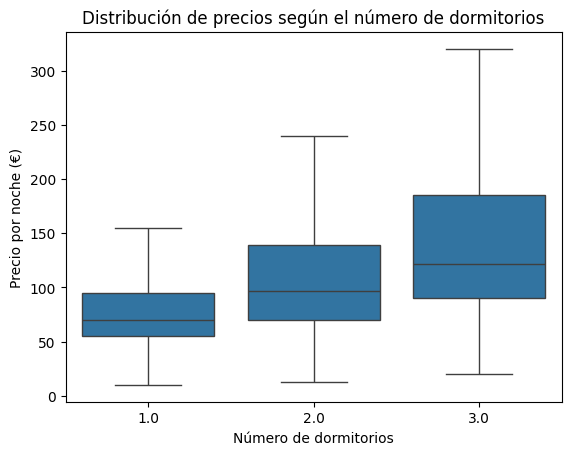

In [31]:
# Distribución de precios según el número de dormitorios

sns.boxplot(
    data=df[df["bedrooms"].isin([1, 2, 3])],
    x="bedrooms",
    y="price",
    showfliers=False
)

plt.title("Distribución de precios según el número de dormitorios")
plt.xlabel("Número de dormitorios")
plt.ylabel("Precio por noche (€)")

plt.show()

El precio mediano aumenta con el número de dormitorios, aunque también crece la dispersión de los precios. Los resultados muestran una asociación positiva entre ambas variables, sin que el número de dormitorios explique por sí solo las diferencias observadas.

### 6.2. Relación entre la capacidad de huéspedes y el precio

Hipótesis: las viviendas con mayor capacidad de huéspedes presentan precios más elevados.

Se comparan los precios de los alojamientos según su capacidad máxima para identificar posibles diferencias entre grupos.

In [32]:
# Precio medio según la capacidad de huéspedes

precio_huespedes = df.groupby("accommodates")["price"].mean().loc[[2, 3, 4, 5, 6]]

precio_huespedes

accommodates
2    117.767425
3    154.726916
4    139.741888
5    160.677579
6    167.546901
Name: price, dtype: float64

In [33]:
# Número de alojamientos según su capacidad

df["accommodates"].value_counts().sort_index()

accommodates
1       85
2     2726
3     1527
4     4715
5     1008
6     1823
7      269
8      440
9       53
10     128
11      22
12      56
13      14
14       9
15       7
16      26
19       1
20       1
23       1
25       1
27       1
Name: count, dtype: int64

El 91,4 % de las viviendas tiene capacidad para entre 2 y 6 huéspedes. Se seleccionan estos grupos por su representatividad para comparar los precios.

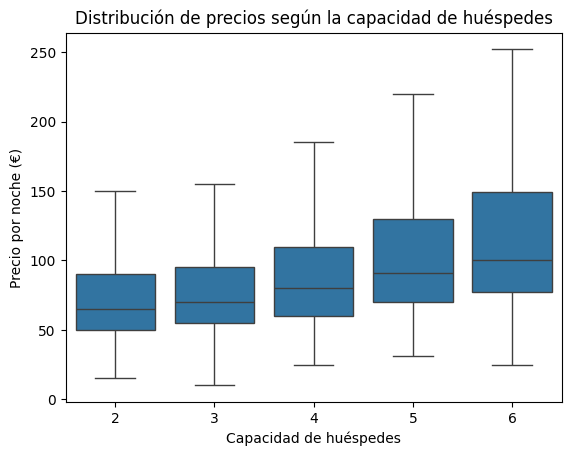

In [34]:
# Distribución de precios según la capacidad de huéspedes
sns.boxplot(
    data=df[df["accommodates"].isin([2, 3, 4, 5, 6])],
    x="accommodates",
    y="price",
    showfliers=False
)

plt.title("Distribución de precios según la capacidad de huéspedes")
plt.xlabel("Capacidad de huéspedes")
plt.ylabel("Precio por noche (€)")

plt.show()

El precio mediano aumenta con la capacidad de alojamiento, acompañado de una mayor dispersión de los precios. Los resultados muestran una asociación positiva, aunque existen diferencias importantes entre viviendas de una misma capacidad.

### 6.3. Relación entre la distancia al centro y el precio

Hipótesis: las viviendas más próximas a la Puerta del Sol presentan precios más elevados.

Se agrupan los alojamientos por tramos de distancia para comparar sus precios y estudiar la posible relación entre ubicación y precio

In [35]:
# Agrupar viviendas según su distancia a Sol

df["grupo_distancia"] = pd.cut(
    df["dist_km_sol"],
    bins=[0, 2, 4, float("inf")],
    labels=["0-2 km", "2-4 km", "4+ km"],
    include_lowest=True
)

In [36]:
# Precio medio por tramo de distancia a Sol

precio_distancia = df.groupby("grupo_distancia", observed=True)["price"].mean()

precio_distancia

grupo_distancia
0-2 km    129.385528
2-4 km    156.422524
4+ km     162.423066
Name: price, dtype: float64

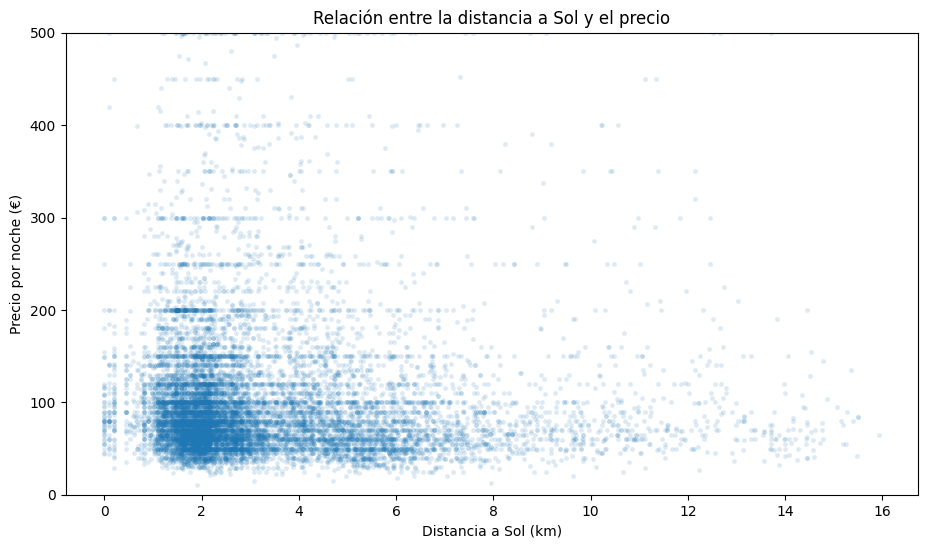

In [37]:
# Relación entre la distancia a Sol y el precio

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="dist_km_sol",
    y="price",
    alpha=0.15,
    s=12,
    linewidth=0
)

plt.title("Relación entre la distancia a Sol y el precio")
plt.xlabel("Distancia a Sol (km)")
plt.ylabel("Precio por noche (€)")
plt.ylim(0, 500)

plt.show()

No se observa una relación lineal clara entre la distancia a Sol y el precio. Los alojamientos más próximos al centro presentan mayor dispersión y concentran buena parte de los precios elevados, aunque también existen viviendas económicas en estas zonas.

### 6.4. Relación entre la condición de Superhost y el precio

Hipótesis: los alojamientos gestionados por anfitriones Superhost presentan precios más elevados.

Se comparan los precios de ambos grupos para evaluar si existen diferencias asociadas a esta distinción.

In [38]:
# Precio medio según la condición de Superhost

df.groupby("host_is_superhost")["price"].mean()

host_is_superhost
0    157.096665
1    121.090307
Name: price, dtype: float64

In [39]:
# Número de alojamientos según la condición de Superhost

df["host_is_superhost"].value_counts()

host_is_superhost
0    10045
1     2868
Name: count, dtype: int64

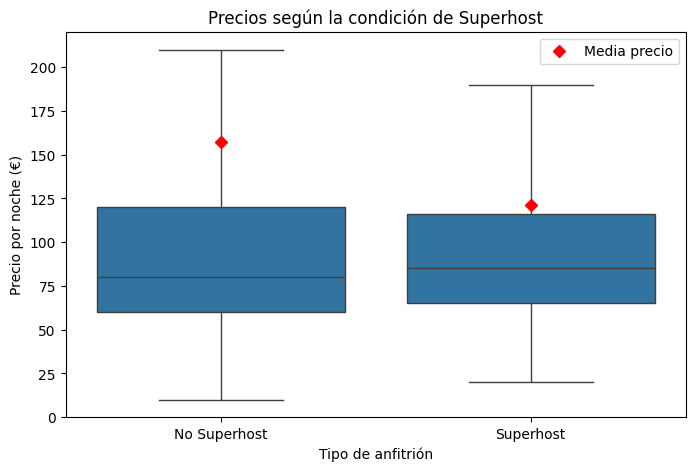

In [40]:
from matplotlib.lines import Line2D

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="host_is_superhost",
    y="price",
    showfliers=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": 6
    }
)

plt.title("Precios según la condición de Superhost")
plt.xlabel("Tipo de anfitrión")
plt.ylabel("Precio por noche (€)")
plt.xticks([0, 1], ["No Superhost", "Superhost"])

# Leyenda para la media
media_legend = Line2D(
    [0], [0],
    marker="D",
    color="w",
    label="Media precio",
    markerfacecolor="red",
    markeredgecolor="red",
    markersize=6
)

plt.legend(handles=[media_legend], loc="upper right")

plt.show()

Los alojamientos No Superhost presentan un precio medio superior (157,10 € frente a 121,09 €), mientras que la mediana es ligeramente mayor entre los Superhost (85 € frente a 80 €). Esta diferencia evidencia la influencia de los precios elevados sobre las medias y no permite afirmar que los Superhost sean sistemáticamente más caros.

### 6.5. Relación entre las valoraciones de los huéspedes y el precio

Hipótesis: los alojamientos con mejores valoraciones presentan precios más elevados.

Se analiza la distribución de las puntuaciones generales de los huéspedes para estudiar posteriormente su relación con el precio de los alojamientos.

In [41]:
# Estadísticas descriptivas de las valoraciones generales

df["review_scores_rating"].describe()

count    10899.000000
mean        91.963391
std          9.276895
min         20.000000
25%         90.000000
50%         94.000000
75%         98.000000
max        100.000000
Name: review_scores_rating, dtype: float64

Las valoraciones generales son elevadas, con una mediana de 94 sobre 100. El análisis de puntuaciones se limita a los 10.899 alojamientos con valoración disponible, sin asignar puntuaciones a los registros ausentes.

In [42]:
# Agrupar los alojamientos según su valoración

df["grupo_rating"] = pd.cut(
    df["review_scores_rating"],
    bins=[0, 90, 95, 100],
    labels=["Baja", "Media", "Alta"]
)

In [43]:
# Precio medio según el grupo de valoración

precio_rating = df.groupby("grupo_rating", observed=True)["price"].mean()

precio_rating

grupo_rating
Baja     125.420142
Media    104.834985
Alta     138.179603
Name: price, dtype: float64

In [44]:
# Número de alojamientos por grupo de valoración

df["grupo_rating"].value_counts()

grupo_rating
Alta     4432
Baja     3237
Media    3230
Name: count, dtype: int64

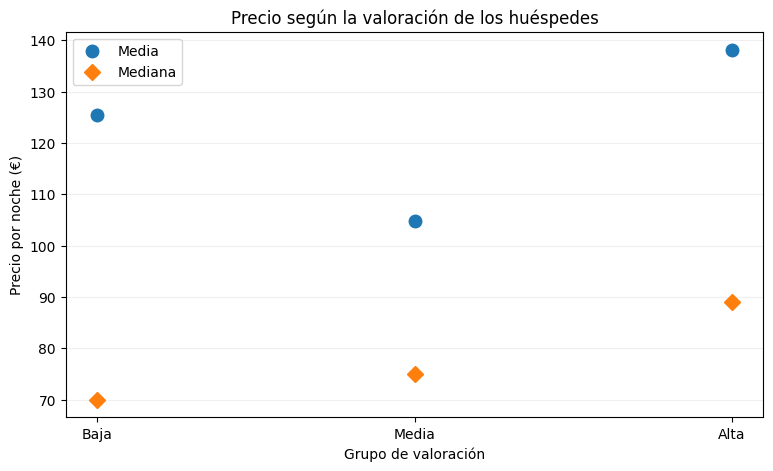

In [45]:
# Calcular media y mediana por grupo de valoración

precios_rating = df.groupby("grupo_rating", observed=True)["price"].agg(["mean", "median"])

# Representar media y mediana
plt.figure(figsize=(9, 5))

plt.plot(precios_rating.index, precios_rating["mean"],
         marker="o", linestyle="None", markersize=9, label="Media")

plt.plot(precios_rating.index, precios_rating["median"],
         marker="D", linestyle="None", markersize=8, label="Mediana")

plt.title("Precio según la valoración de los huéspedes")
plt.xlabel("Grupo de valoración")
plt.ylabel("Precio por noche (€)")
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.show()

El precio mediano aumenta de 70 € a 89 € entre los grupos de valoración baja y alta. Sin embargo, las medias no siguen una progresión continua, lo que evidencia la influencia de precios elevados. Los resultados sugieren una asociación positiva entre valoración y precio habitual, sin establecer causalidad.

### 6.6. Diferencias de precio entre distritos de Madrid

Hipótesis: los precios de los alojamientos presentan diferencias según el distrito en el que se encuentran.

Se comparan los precios entre distritos para identificar diferencias geográficas y valorar la posible influencia de la ubicación.

In [46]:
# Precio medio de los alojamientos por distrito

precio_distrito = (
    df.groupby("neighbourhood_group")["price"]
    .mean()
    .sort_values(ascending=False)
)

precio_distrito

neighbourhood_group
San Blas - Canillejas    475.923077
Usera                    394.487603
Vicálvaro                212.466667
Latina                   196.559524
Hortaleza                183.192547
Salamanca                176.132696
Fuencarral - El Pardo    172.098361
Tetuán                   162.342412
Moncloa - Aravaca        148.640867
Villa de Vallecas        142.451613
Chamberí                 140.445323
Centro                   140.184882
Retiro                   139.332547
Moratalaz                134.852941
Chamartín                128.359890
Arganzuela               125.160572
Ciudad Lineal            122.340000
Barajas                  113.653846
Villaverde               101.794872
Carabanchel               99.292969
Puente de Vallecas        80.630081
Name: price, dtype: float64

In [47]:
# Número de alojamientos por distrito

df["neighbourhood_group"].value_counts()

neighbourhood_group
Centro                   7210
Salamanca                 942
Chamberí                  759
Arganzuela                629
Tetuán                    514
Retiro                    424
Chamartín                 364
Moncloa - Aravaca         323
Carabanchel               256
Latina                    252
Ciudad Lineal             250
Puente de Vallecas        246
San Blas - Canillejas     169
Hortaleza                 161
Fuencarral - El Pardo     122
Usera                     121
Barajas                    52
Villaverde                 39
Moratalaz                  34
Villa de Vallecas          31
Vicálvaro                  15
Name: count, dtype: int64

Centro concentra el 55,8 % de las viviendas completas. Las diferencias de tamaño entre distritos y la posible influencia de precios extremos requieren cautela al comparar los precios medios.

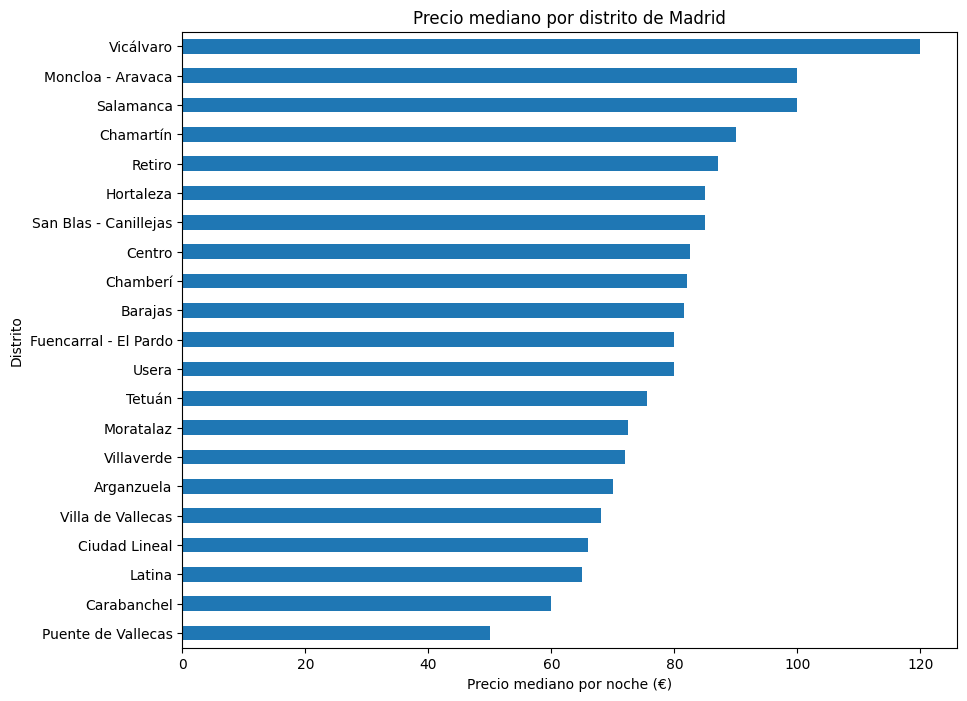

In [48]:
# Precio mediano por distrito

precio_mediano_distrito = (
    df.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=True)
)

# Visualización
plt.figure(figsize=(10, 8))

precio_mediano_distrito.plot(kind="barh")

plt.title("Precio mediano por distrito de Madrid")
plt.xlabel("Precio mediano por noche (€)")
plt.ylabel("Distrito")

plt.show()

Los precios medianos presentan diferencias entre distritos. Vicálvaro registra el valor más elevado, aunque su muestra es reducida (15 alojamientos). La comparación con las medias muestra cómo los precios extremos pueden alterar las clasificaciones territoriales.

### 6.7. Relación entre el barrio y el precio

Hipótesis: los precios de los alojamientos presentan diferencias según el barrio en el que se encuentran.

Se comparan los precios entre barrios para identificar diferencias geográficas y valorar su relevancia en el mercado de alojamientos.

In [49]:
# Precio medio de los alojamientos por barrio

precio_barrio = (
    df.groupby("neighbourhood")["price"]
    .mean()
    .sort_values(ascending=False)
)

precio_barrio

neighbourhood
San Blas              473.505882
Usera                 394.487603
Ciudad Jardin         267.722222
Valdeacederas         239.968750
Berruguete            225.880000
                         ...    
Prosperidad            85.532258
Puente de Vallecas     82.732794
Acacias                78.538462
Adelfas                78.379310
Castilla               61.526316
Name: price, Length: 66, dtype: float64

In [50]:
# Número de alojamientos por barrio

df["neighbourhood"].value_counts()

neighbourhood
Centro            3754
Embajadores        858
Malasaña           541
Salamanca          484
Palacio            463
                  ... 
Vicálvaro           15
Vallehermosa        15
El Tréntaiseis      12
Atocha               6
Estrella             6
Name: count, Length: 66, dtype: int64

La distribución de viviendas entre los 66 barrios es desigual: Centro concentra el 29,1 % de la muestra, mientras que algunos barrios tienen muy pocos registros. Se tendrá en cuenta el tamaño de los grupos al comparar precios.

In [51]:
# Número de viviendas en los cinco barrios con mayor precio medio

conteo_barrio = df["neighbourhood"].value_counts()

conteo_barrio.loc[
    ["San Blas", "Usera", "Ciudad Jardin", "Valdeacederas", "Berruguete"]
]

neighbourhood
San Blas         170
Usera            121
Ciudad Jardin     18
Valdeacederas     32
Berruguete        50
Name: count, dtype: int64

Entre los cinco barrios con mayor precio medio existen diferencias importantes de tamaño muestral, desde 18 hasta 170 viviendas. Esto limita la comparación y refuerza la necesidad de considerar indicadores menos sensibles a los valores extremos.

In [52]:
# Calcular el precio mediano por barrio

precio_mediano_barrio = (
    df.groupby("neighbourhood")["price"]
    .median()
    .sort_values(ascending=False)
)

# Seleccionar los cinco barrios con mayor y menor mediana

top_5 = precio_mediano_barrio.head(5)
bottom_5 = precio_mediano_barrio.tail(5)

print("Barrios con mayor precio mediano:")
print(top_5)

print("\nBarrios con menor precio mediano:")
print(bottom_5)

Barrios con mayor precio mediano:
neighbourhood
El Viso       150.0
Castellana    140.0
Recoletos     129.5
Vicálvaro     120.0
Argüelles     110.0
Name: price, dtype: float64

Barrios con menor precio mediano:
neighbourhood
Arapiles              65.0
Valdeacederas         62.5
Castilla              60.0
Carabanchel           60.0
Puente de Vallecas    50.0
Name: price, dtype: float64


In [53]:
# Número de viviendas en los barrios seleccionados

conteo_barrio.loc[top_5.index.tolist() + bottom_5.index.tolist()]

neighbourhood
El Viso                21
Castellana             58
Recoletos             118
Vicálvaro              15
Argüelles             125
Arapiles               49
Valdeacederas          32
Castilla               19
Carabanchel           257
Puente de Vallecas    247
Name: count, dtype: int64

Se establece un mínimo de 50 viviendas por barrio para reducir la influencia de grupos con pocas observaciones. Entre los barrios que cumplen este criterio, se seleccionan los cinco con mayor y menor precio mediano.

In [54]:
# Seleccionar barrios con al menos 50 viviendas

barrios_validos = conteo_barrio[conteo_barrio >= 50].index

# Calcular el precio mediano de los barrios seleccionados

precio_mediano_barrio = (
    df[df["neighbourhood"].isin(barrios_validos)]
    .groupby("neighbourhood")["price"]
    .median()
    .sort_values(ascending=False)
)

# Cinco barrios con mayor y menor precio mediano

top_5 = precio_mediano_barrio.head(5)
bottom_5 = precio_mediano_barrio.tail(5)

print("Barrios con mayor precio mediano:")
print(top_5)

print("\nBarrios con menor precio mediano:")
print(bottom_5)

Barrios con mayor precio mediano:
neighbourhood
Castellana    140.0
Recoletos     129.5
Argüelles     110.0
Salamanca     100.0
Goya           99.0
Name: price, dtype: float64

Barrios con menor precio mediano:
neighbourhood
Ciudad Lineal         66.0
Guindalera            66.0
Aluche                65.0
Carabanchel           60.0
Puente de Vallecas    50.0
Name: price, dtype: float64


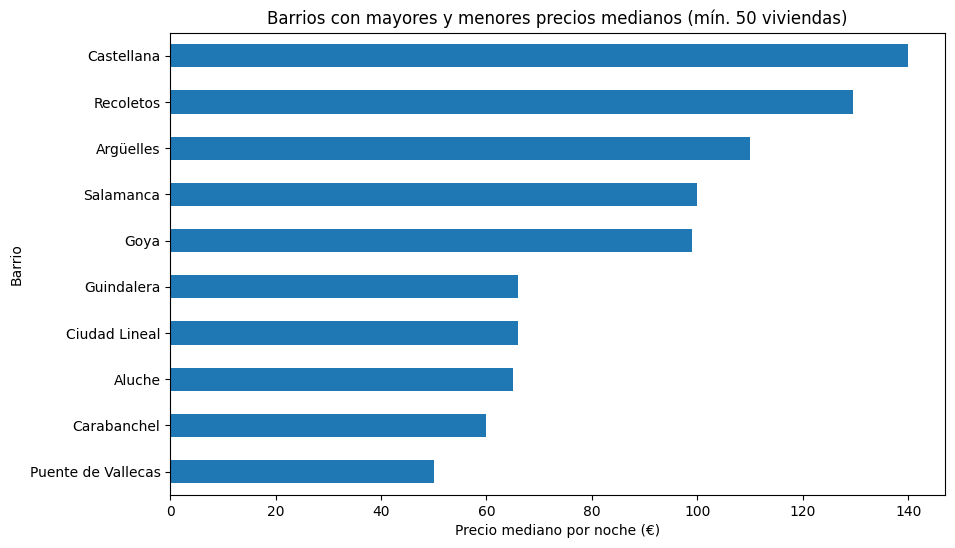

In [55]:
# Unir los barrios seleccionados y ordenar por precio mediano

precios_barrios = pd.concat([top_5, bottom_5]).sort_values()

# Comparar los precios medianos
plt.figure(figsize=(10, 6))

precios_barrios.plot(kind="barh")

plt.title("Barrios con mayores y menores precios medianos (mín. 50 viviendas)")
plt.xlabel("Precio mediano por noche (€)")
plt.ylabel("Barrio")

plt.show()

Entre los barrios con al menos 50 viviendas, Castellana presenta el mayor precio mediano (140 €) y Puente de Vallecas el menor (50 €). La diferencia de 90 € evidencia variaciones geográficas relevantes, aunque no permite atribuirlas exclusivamente a la ubicación.

### 6.8. Análisis de las correlaciones

In [56]:
# Correlaciones entre el precio y las variables numéricas

variables = [
    "price",
    "bedrooms",
    "bathrooms",
    "accommodates",
    "dist_km_sol",
    "number_of_reviews",
    "review_scores_rating",
    "host_seniority"
]

df[variables].corr()

,price,bedrooms,bathrooms,accommodates,dist_km_sol,number_of_reviews,review_scores_rating,host_seniority
price,1.000000,0.075337,0.085655,0.061643,0.039488,-0.079292,-0.015573,-0.056339
bedrooms,0.075337,1.000000,0.622125,0.751306,0.080186,-0.049409,0.066073,0.004890
bathrooms,0.085655,0.622125,1.000000,0.567089,0.038067,-0.054918,0.090611,0.015389
accommodates,0.061643,0.751306,0.567089,1.000000,-0.019603,0.007822,0.002330,-0.031357
dist_km_sol,0.039488,0.080186,0.038067,-0.019603,1.000000,-0.180514,-0.011114,-0.106041
number_of_reviews,-0.079292,-0.049409,-0.054918,0.007822,-0.180514,1.000000,0.102183,0.265200
review_scores_rating,-0.015573,0.066073,0.090611,0.002330,-0.011114,0.102183,1.000000,0.093494
host_seniority,-0.056339,0.004890,0.015389,-0.031357,-0.106041,0.265200,0.093494,1.000000


La matriz de correlaciones muestra relaciones lineales muy débiles entre el precio y las variables numéricas analizadas, con coeficientes inferiores a 0,09 en valor absoluto.

Por otra parte, se identifican correlaciones positivas entre dormitorios, capacidad de huéspedes y baños, especialmente entre dormitorios y capacidad (0,751).

Estos resultados complementan las comparaciones anteriores y muestran que las diferencias de precios observadas entre grupos no se traducen necesariamente en relaciones lineales fuertes.

## 7. Resultados y conclusiones

### 7.1. Síntesis de resultados

El análisis de 12.913 viviendas completas de Airbnb en Madrid ha permitido identificar los siguientes resultados:

| Factor analizado | Resultado principal |
|---|---|
| **Número de dormitorios** | Los precios medianos aumentan entre las viviendas de 1, 2 y 3 dormitorios, junto con una mayor dispersión. |
| **Capacidad de huéspedes** | Se observa un aumento general del precio mediano entre alojamientos de 2 a 6 huéspedes. |
| **Distancia a Sol** | No se identifica una relación lineal clara con el precio. |
| **Condición de Superhost** | Los Superhost presentan una mediana ligeramente superior (85 € frente a 80 €), pero una media inferior. |
| **Valoraciones de los huéspedes** | Los precios medianos aumentan entre los grupos de valoración baja, media y alta, aunque las medias no siguen la misma progresión. |
| **Distrito** | Existen diferencias en los precios medianos entre distritos, con tamaños muestrales desiguales. |
| **Barrio** | Entre los barrios con al menos 50 viviendas, Castellana presenta la mayor mediana (140 €) y Puente de Vallecas la menor (50 €). |
| **Correlaciones** | Las variables numéricas presentan correlaciones lineales muy débiles con el precio. Destaca la relación entre dormitorios y capacidad de huéspedes (0,751). |

En conjunto, el análisis identifica diferencias de precios entre grupos de alojamientos, aunque estas no se traducen en relaciones lineales fuertes ni permiten determinar la importancia relativa de cada factor.

### 7.2. Conclusiones y limitaciones

**Conclusiones**

El análisis muestra que los precios de los alojamientos Airbnb en Madrid presentan diferencias asociadas a sus características físicas, ubicación y valoraciones.

Las viviendas con más dormitorios y mayor capacidad de huéspedes tienden a presentar precios medianos superiores. También se identifican diferencias entre barrios y distritos, mientras que la distancia a Sol y la condición de Superhost no muestran una relación uniforme con el precio.

Sin embargo, las correlaciones lineales entre el precio y las variables numéricas analizadas son muy débiles. Esto indica que las diferencias observadas entre grupos no se traducen necesariamente en relaciones lineales fuertes.

La comparación entre medias y medianas evidencia la influencia de los precios extremos, por lo que resulta fundamental seleccionar indicadores adecuados antes de interpretar los resultados.

**Implicaciones para el negocio**

Para orientar una estrategia de precios, se recomienda comparar cada vivienda con alojamientos de características y ubicación similares, considerando sus precios habituales y no únicamente los promedios del mercado.

**Limitaciones**

El estudio es descriptivo y no permite establecer relaciones causales ni determinar la importancia relativa de cada variable. Además, existen diferencias en los tamaños muestrales, valores extremos y alojamientos sin valoración.

No se dispone de información sobre ocupación, costes o rentabilidad, por lo que no es posible determinar el precio óptimo de cada vivienda.